# Label-based Drift Detection on Elec2

**Task:** (1) đọc Elec2 từ River và đánh giá prequential, (2) no-change baseline, (3) ADWIN/DDM trên luồng lỗi, (4) so sánh frozen model với retrain-on-drift. Biểu đồ accuracy theo thời gian và đánh dấu drift.

## 0. Cài đặt và tái lập

Chạy trên Python 3.11. River `Elec2()` có thể tải dữ liệu qua mạng ở lần đầu; cần internet hoặc dữ liệu đã được cache. Với môi trường mới, chạy lệnh sau **trong terminal cùng virtualenv**:

In [1]:
import platform
from collections import deque
from dataclasses import dataclass

import matplotlib.pyplot as plt
import pandas as pd
import river
from river import datasets, drift, naive_bayes

print("Python:", platform.python_version())
print("River:", river.__version__)

WARMUP = 2_000  # các mẫu dùng để huấn luyện ban đầu; không tính vào so sánh
RETRAIN_WINDOW = 2_000  # chỉ dùng nhãn đã quan sát trước thời điểm drift
ACCURACY_WINDOW = 500  # rolling accuracy để nhìn phản ứng theo thời gian
ADWIN_DELTA = 0.002
DDM_MIN_INSTANCES = 30


def make_model():
    # Gaussian Naive Bayes: mô hình tăng dần, không yêu cầu chuẩn hoá feature.
    return naive_bayes.GaussianNB()


def make_detector(kind):
    if kind == "ADWIN":
        return drift.ADWIN(delta=ADWIN_DELTA)
    if kind == "DDM":
        return drift.binary.DDM(warm_start=DDM_MIN_INSTANCES)
    raise ValueError(f"Detector không được hỗ trợ: {kind}")

Python: 3.11.11
River: 0.27.0


## 1. Dataset Elec2

Elec2 là bài toán phân loại nhị phân biến động giá điện ở New South Wales, Australia. Dữ liệu theo dòng thời gian, gồm **45.312 mẫu**, **8 thuộc tính** và nhãn `True`/`False` đại diện cho **UP/DOWN**. Những giá trị đầu vào như giá điện, nhu cầu và dòng trao đổi là *đặc trưng*; nhãn chỉ được dùng **sau** khi đưa ra dự đoán.

Không dùng `train_test_split(shuffle=True)` trong bài toán này.

In [2]:
dataset = datasets.Elec2()
print(dataset)
stream = iter(dataset)
first_x, first_y = next(stream)
print("Sample features:", first_x)
print("Sample label:", first_y)
assert len(first_x) == 8
assert isinstance(first_y, bool)
# Các vòng đánh giá bên dưới luôn tạo iterator Elec2() mới từ đầu.

Electricity prices in New South Wales.

This is a binary classification task, where the goal is to predict if the price of electricity
will go up or down.

This data was collected from the Australian New South Wales Electricity Market. In this market,
prices are not fixed and are affected by demand and supply of the market. They are set every
five minutes. Electricity transfers to/from the neighboring state of Victoria were done to
alleviate fluctuations.

      Name  Elec2                                                      
      Task  Binary classification                                      
   Samples  45,312                                                     
  Features  8                                                          
    Sparse  False                                                      
      Path  /home/trggonos/river_data/Elec2/electricity.csv            
       URL  https://maxhalford.github.io/files/datasets/electricity.zip
      Size  2.95 MiB               

## 2. No-change baseline — dự đoán nhãn trước đó

Với mẫu thứ `t`, dự đoán `ŷₜ = yₜ₋₁`. Nhãn của mẫu hiện tại chỉ dùng để tính accuracy, **sau đó** mới lưu làm nhãn trước cho lượt tiếp theo. Bỏ qua mẫu đầu vì không có nhãn trước để dự đoán.

Baseline này khác với mô hình cố định (frozen model) ở phần 4: nó có cập nhật bộ nhớ **một nhãn gần nhất** dù không huấn luyện mô hình ML.

In [3]:
previous_label = None
baseline_correct = 0
baseline_total = 0
baseline_history = []

for i, (x, y) in enumerate(datasets.Elec2(), start=1):
    if previous_label is not None:
        correct = int(previous_label == y)
        baseline_correct += correct
        baseline_total += 1
        baseline_history.append({"index": i, "correct": correct})
    previous_label = y

baseline_acc = baseline_correct / baseline_total
print(f"No-change accuracy = {baseline_acc:.4%} ({baseline_correct}/{baseline_total})")
assert baseline_total == i - 1

No-change accuracy = 85.3303% (38664/45311)


## 3. Prequential evaluation và ADWIN/DDM trên luồng lỗi

Đầu tiên xây một mô hình **online-learning reference** để có luồng lỗi theo giao thức test-then-train:

1. Gọi `predict_one(x)` trước khi thấy nhãn.
2. Tạo lỗi nhị phân `error = int(y_pred != y)`.
3. Đưa **chính cùng lỗi** vào ADWIN và DDM để so sánh công bằng vị trí cảnh báo.
4. Sau khi detector nhận lỗi, mới gọi `learn_one(x, y)`.

Mô hình ở bước này học sau mỗi mẫu; nó chỉ dùng để khảo sát detectors, **không phải** mô hình frozen dùng trong so sánh ở phần 4. Bỏ qua dự đoán `None` (mô hình chưa sẵn sàng).

In [4]:
reference_model = make_model()
monitor_adwin = make_detector("ADWIN")
monitor_ddm = make_detector("DDM")
reference_log = []
monitor_events = []

for i, (x, y) in enumerate(datasets.Elec2(), start=1):
    pred = reference_model.predict_one(x)  # TEST
    if pred is not None:
        err = int(pred != y)
        for name, det in [("ADWIN", monitor_adwin), ("DDM", monitor_ddm)]:
            det.update(err)
            if det.drift_detected:
                monitor_events.append({"index": i, "detector": name, "error": err})
        reference_log.append({"index": i, "correct": 1 - err})
    reference_model.learn_one(x, y)  # TRAIN: chỉ sau khi TEST

reference_df = pd.DataFrame(reference_log)
monitor_events_df = pd.DataFrame(monitor_events, columns=["index", "detector", "error"])
print("Reference prequential accuracy:", f"{reference_df['correct'].mean():.4%}")
print("Reference error-stream drift counts:")
print(
    monitor_events_df["detector"].value_counts().reindex(["ADWIN", "DDM"], fill_value=0).to_string()
)
display(monitor_events_df.head(30))

Reference prequential accuracy: 72.8763%
Reference error-stream drift counts:
detector
ADWIN     74
DDM      138


,index,detector,error
0,185,DDM,1
1,225,ADWIN,0
2,415,DDM,1
3,454,DDM,1
4,599,DDM,1
5,1278,DDM,1
6,1557,DDM,1
7,1658,DDM,1
8,1797,DDM,1
9,2136,DDM,1


## 4. Thí nghiệm chính — no update vs retrain on drift

**Thiết lập công bằng:**

- Cả ba mô hình đều học từ **cùng 2.000 mẫu đầu (warm-up)**, theo thứ tự thời gian.
- Sau warm-up, **Frozen** không được `learn_one` nữa.
- **Retrain + ADWIN** và **Retrain + DDM** đều được đánh giá dự đoán trước khi nhìn thấy nhãn. Mỗi mô hình có detector lỗi riêng.
- Khi một detector báo drift, tạo một mô hình mới và huấn luyện lại trên **tối đa 2.000 mẫu lịch sử đã xuất hiện trước mẫu hiện tại**, rồi reset detector. **Không** đưa nhãn hiện tại vào mô hình mới trước bước dự đoán của mẫu hiện tại.
- Dữ liệu lịch sử vẫn cập nhật sau khi nhãn được quan sát, nhưng mô hình chỉ update tại drift event. Không có incremental learning liên tục trên tập đánh giá.
- Drift points của hai nhánh retrain có thể khác với các điểm ở phần 3 vì mô hình và luồng lỗi khác nhau.

Đây là thiết kế *retrain from scratch on a recent labeled window*, không phải `partial_fit` liên tục. Không có trigger nếu model không suy giảm đủ để detector phát hiện.

In [5]:
@dataclass
class Branch:
    name: str
    model: object
    detector: object = None
    n_updates: int = 0


def evaluate_strategies():
    frozen = Branch("No update", make_model())
    branches = {
        "No update": frozen,
        "Retrain + ADWIN": Branch("Retrain + ADWIN", make_model(), make_detector("ADWIN")),
        "Retrain + DDM": Branch("Retrain + DDM", make_model(), make_detector("DDM")),
    }
    past = deque(maxlen=RETRAIN_WINDOW)
    records = []
    events = []

    for i, (x, y) in enumerate(datasets.Elec2(), start=1):
        if i <= WARMUP:
            for branch in branches.values():
                branch.model.learn_one(x, y)
            past.append((dict(x), y))
            continue

        # TEST: dự đoán bằng các trạng thái mô hình tại đầu mẫu i.
        for name, branch in branches.items():
            pred = branch.model.predict_one(x)
            correct = int(pred == y) if pred is not None else 0
            records.append({"index": i, "strategy": name, "correct": correct})

            # Sau khi có nhãn thực tế mới cập nhật error detector.
            if branch.detector is not None:
                branch.detector.update(1 - correct)
                if branch.detector.drift_detected:
                    events.append({"index": i, "strategy": name, "training_samples": len(past)})
                    fresh_model = make_model()
                    # TRAIN từ những quan sát TRƯỚC mẫu i, bảo vệ no-leakage.
                    for old_x, old_y in past:
                        fresh_model.learn_one(old_x, old_y)
                    branch.model = fresh_model
                    branch.detector = make_detector(name.split("+ ")[1])
                    branch.n_updates += 1

        # Nhãn hiện tại chỉ được phép đi vào bộ đệm SAU khi đánh giá xong.
        past.append((dict(x), y))

    return (
        pd.DataFrame(records),
        pd.DataFrame(events, columns=["index", "strategy", "training_samples"]),
        branches,
    )


results_df, update_events_df, branches = evaluate_strategies()
summary = (
    results_df.groupby("strategy", sort=False)
    .agg(n=("correct", "size"), accuracy=("correct", "mean"))
    .reset_index()
)
summary["retrain_count"] = summary["strategy"].map(lambda k: branches[k].n_updates)
summary["accuracy_pct"] = (summary["accuracy"] * 100).round(2)
print("THÍ NGHIỆM CHÍNH — ngoài tập warm-up")
display(summary[["strategy", "n", "accuracy_pct", "retrain_count"]])
print("Drift-triggered retrain events:")
display(update_events_df)
assert results_df.groupby("strategy").size().nunique() == 1
assert all(idx > WARMUP for idx in update_events_df["index"])
assert summary.loc[summary.strategy == "No update", "retrain_count"].iloc[0] == 0

THÍ NGHIỆM CHÍNH — ngoài tập warm-up


,strategy,n,accuracy_pct,retrain_count
0,No update,43312,67.01,0
1,Retrain + ADWIN,43312,73.52,63
2,Retrain + DDM,43312,75.85,158


Drift-triggered retrain events:


,index,strategy,training_samples
0,2032,Retrain + DDM,2000
1,2132,Retrain + DDM,2000
2,2217,Retrain + DDM,2000
3,2256,Retrain + ADWIN,2000
4,2291,Retrain + DDM,2000
...,...,...,...
216,44368,Retrain + ADWIN,2000
217,44436,Retrain + DDM,2000
218,44616,Retrain + DDM,2000
219,44660,Retrain + DDM,2000


## 5. Deliverable: Accuracy over time + drift points

**Biểu đồ chính:** đường accuracy trượt trên 500 dự đoán gần nhất. Dấu chấm thể hiện lần detector phát hiện drift và kích hoạt retraining trong nhánh tương ứng. Đường No update không có retrain point.

Rolling accuracy nhạy với thay đổi gần đây hơn cumulative accuracy; có thể chỉnh `ACCURACY_WINDOW`. Điểm drift chỉ là **điểm phát hiện**, không phải ground-truth drift timestamp.

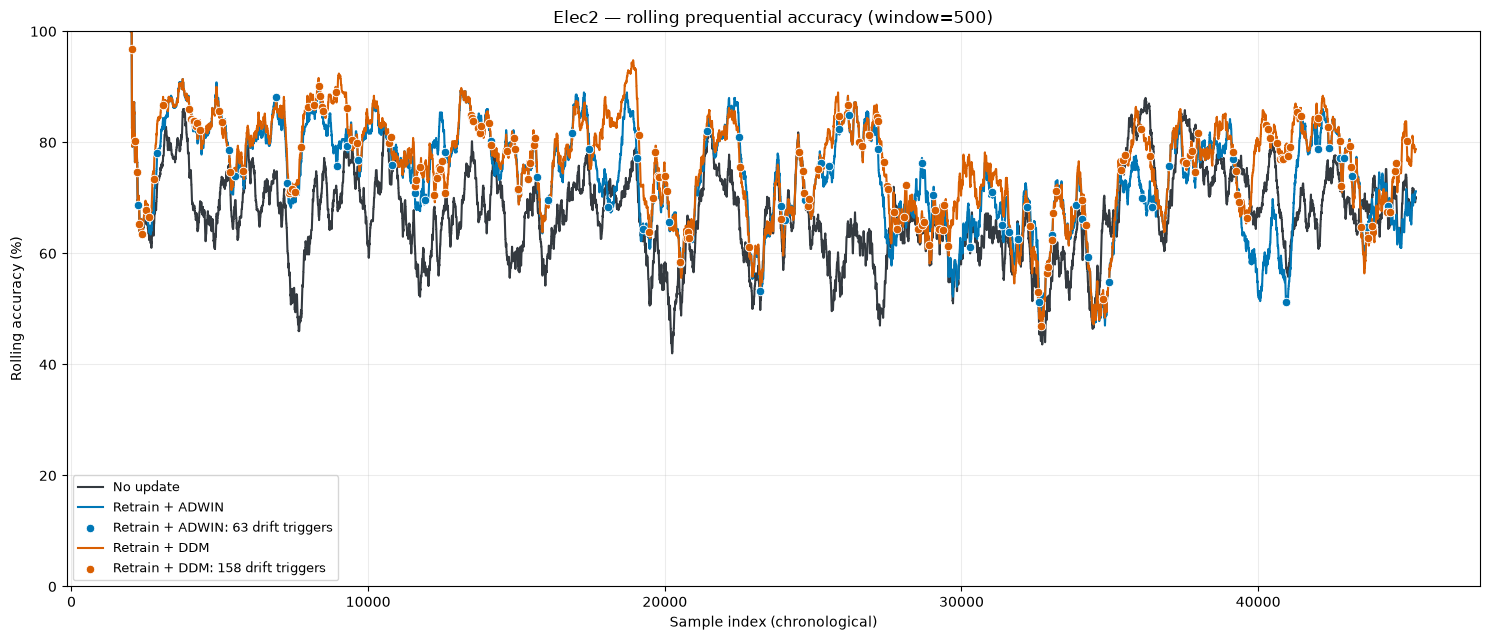

Saved: elec2_accuracy_drift.png


In [6]:
plot_df = results_df.copy()
plot_df["rolling_accuracy"] = plot_df.groupby("strategy", sort=False)["correct"].transform(
    lambda s: s.rolling(ACCURACY_WINDOW, min_periods=1).mean()
)

fig, ax = plt.subplots(figsize=(15, 6.5))
style = {
    "No update": ("#343a40", "-"),
    "Retrain + ADWIN": ("#0077b6", "-"),
    "Retrain + DDM": ("#d95f02", "-"),
}
for name, frame in plot_df.groupby("strategy", sort=False):
    col, ls = style[name]
    ax.plot(frame["index"], 100 * frame["rolling_accuracy"], color=col, ls=ls, lw=1.5, label=name)
    sub = update_events_df[update_events_df["strategy"] == name]
    if len(sub):
        points = frame.set_index("index")["rolling_accuracy"].reindex(sub["index"])
        ax.scatter(
            sub["index"],
            100 * points.to_numpy(),
            s=38,
            color=col,
            edgecolors="white",
            linewidths=0.65,
            zorder=5,
            label=f"{name}: {len(sub)} drift triggers",
        )

ax.set(
    title=f"Elec2 — rolling prequential accuracy (window={ACCURACY_WINDOW})",
    xlabel="Sample index (chronological)",
    ylabel="Rolling accuracy (%)",
)
ax.grid(alpha=0.23)
ax.set_ylim(0, 100)
ax.legend(loc="best", fontsize=9)
plt.tight_layout()
plt.savefig("elec2_accuracy_drift.png", dpi=170, bbox_inches="tight")
plt.show()
print("Saved: elec2_accuracy_drift.png")

## 6. Biểu đồ detector — ADWIN và DDM trên cùng error stream

Đây là các điểm được phát hiện trong phần 3 khi mô hình reference học liên tục. Trục tung là accuracy rolling của mô hình reference, không phải nhánh adaptive. Hai đồ thị khác nhau do hai câu hỏi thực nghiệm khác nhau.

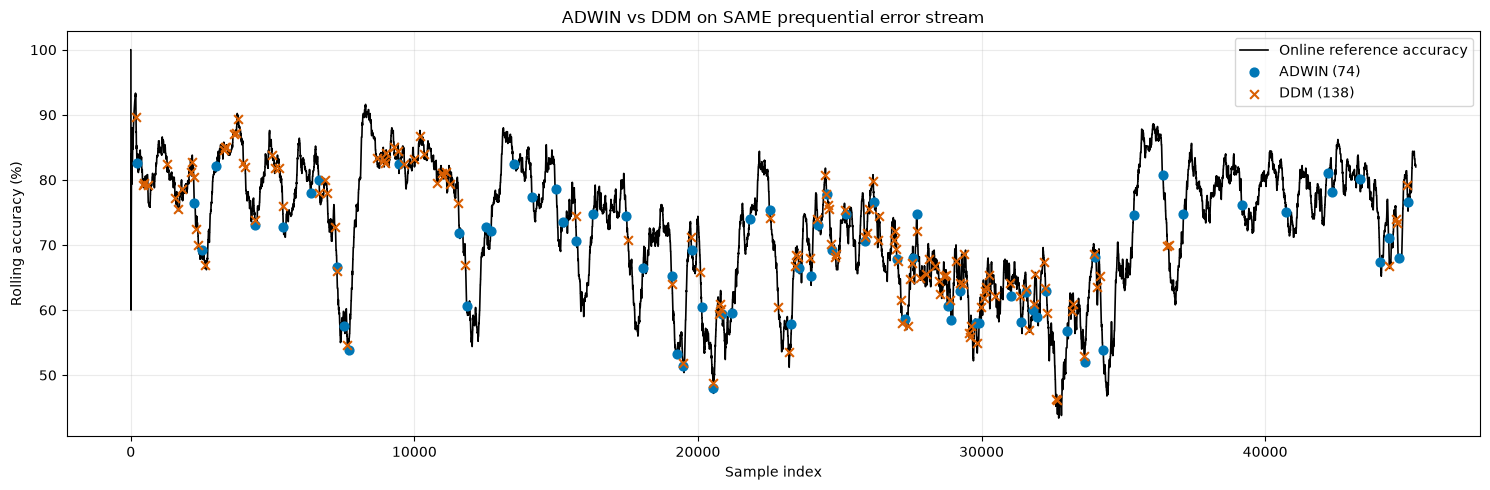

In [7]:
ref = reference_df.copy()
ref["rolling_accuracy"] = ref["correct"].rolling(ACCURACY_WINDOW, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(
    ref["index"],
    ref["rolling_accuracy"] * 100,
    c="black",
    lw=1.2,
    label="Online reference accuracy",
)
for name, color, marker in [("ADWIN", "#0077b6", "o"), ("DDM", "#d95f02", "x")]:
    subset = monitor_events_df[monitor_events_df["detector"] == name]
    ypoints = ref.set_index("index")["rolling_accuracy"].reindex(subset["index"])
    ax.scatter(
        subset["index"],
        ypoints * 100,
        label=f"{name} ({len(subset)})",
        color=color,
        marker=marker,
        s=40,
        zorder=5,
    )
ax.set(
    xlabel="Sample index",
    ylabel="Rolling accuracy (%)",
    title="ADWIN vs DDM on SAME prequential error stream",
)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig("elec2_detector_points.png", dpi=170, bbox_inches="tight")
plt.show()

## 7. Kết luận tự động và giới hạn nghiên cứu

- **No-change baseline:** dùng nhãn mẫu trước; là benchmark chuỗi thời gian đơn giản, không dùng features.
- **Online reference:** học sau mỗi mẫu, đánh giá bằng test-then-train; dùng để so sánh ADWIN với DDM trên *cùng* luồng lỗi.
- **Frozen:** học trong warm-up, sau đó không học nữa.
- **Retrain:** chỉ tạo mô hình mới khi ADWIN/DDM báo drift, huấn luyện trên nhãn đã xuất hiện trong quá khứ.

**Hạn chế:** Elec2 không cung cấp ground-truth timestamps của concept drift; drift points chỉ là cảnh báo detector. Đây không phải phép đo detection-delay hay false-alarm chính thức. Việc đánh giá giả định nhãn có ngay sau dự đoán. Baseline no-change có 45.311 lượt dự đoán, còn so sánh ML chỉ chấm từ mẫu 2.001; không nên so sánh trực tiếp các accuracy khác window mà không chú thích.

**Ý nghĩa của kết quả:** Nếu retrain accuracy cao hơn frozen, có bằng chứng rằng cập nhật theo detector hữu ích *với cấu hình này*. Nếu thấp hơn, điều đó vẫn là kết quả hợp lệ: detector có thể báo drift không liên quan hiệu quả mô hình, hoặc retrain window chưa tối ưu. Không kết luận mọi concept drift đều đã được phát hiện.


In [8]:
frozen_acc = float(summary.loc[summary.strategy == "No update", "accuracy"].iloc[0])
print(f"No-change baseline (all possible steps): {baseline_acc:.2%}")
print(f"Online reference prequential: {reference_df.correct.mean():.2%}")
for _, row in summary.iterrows():
    print(f"{row['strategy']}: {row['accuracy']:.2%} | retrains: {row['retrain_count']}")
    if row["strategy"] != "No update":
        delta = row["accuracy"] - frozen_acc
        print(f"  Δ vs frozen: {delta:+.2%} points")
print("Detection locations reference:")
for k in ["ADWIN", "DDM"]:
    print(k, monitor_events_df.loc[monitor_events_df.detector == k, "index"].tolist())

No-change baseline (all possible steps): 85.33%
Online reference prequential: 72.88%
No update: 67.01% | retrains: 0
Retrain + ADWIN: 73.52% | retrains: 63
  Δ vs frozen: +6.51% points
Retrain + DDM: 75.85% | retrains: 158
  Δ vs frozen: +8.85% points
Detection locations reference:
ADWIN [225, 2241, 2497, 3009, 4385, 5377, 6337, 6625, 7265, 7521, 7681, 9473, 11585, 11841, 12513, 12705, 13505, 14145, 14977, 15233, 15713, 16289, 17473, 18049, 19073, 19265, 19489, 19777, 20129, 20545, 20833, 21185, 21825, 22529, 23297, 23553, 24001, 24225, 24545, 24737, 25217, 25889, 26209, 27009, 27297, 27585, 27713, 28801, 28929, 29249, 29793, 29921, 31041, 31393, 31585, 31809, 31969, 32257, 33025, 33633, 33985, 34273, 35361, 36385, 37121, 39169, 40737, 42209, 42369, 43329, 44065, 44353, 44705, 45025]
DDM [185, 415, 454, 599, 1278, 1557, 1658, 1797, 2136, 2173, 2216, 2292, 2380, 2614, 3296, 3328, 3361, 3641, 3708, 3775, 3970, 4028, 4378, 4976, 5068, 5234, 5354, 6652, 6832, 6924, 7191, 7270, 7635, 8671, 

## 8. Checklist nghiệm thu

- [x] Elec2 từ River, đánh giá theo thứ tự gốc.
- [x] No-change baseline = previous label, báo cáo accuracy.
- [x] ADWIN/DDM trên **cùng prequential 0/1 error stream**, ghi chỉ số mẫu phát hiện.
- [x] Frozen model và 2 nhánh retrain khi có drift; tránh dùng nhãn tương lai.
- [x] Accuracy over time và drift points, xuất PNG.
- [x] Báo cáo so sánh accuracy + retrain count.

**Nguồn tham khảo:** [River Elec2](https://riverml.xyz/), [River ADWIN implementation](https://github.com/online-ml/river/blob/main/river/drift/adwin.py), [River drift DDM](https://riverml.xyz/).